<a href="https://colab.research.google.com/github/shocolade-cell/shocolade-repo/blob/main/F26_DLAI_Lab2_Keras_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


SYSTEM LOG: Running on Hardware Accelerator: [CPU]

SYSTEM LOG: Loading the MNIST training dataset...


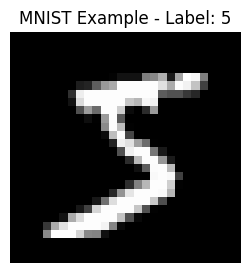

Image array shape: (28, 28)
Each image contains 28 x 28 grayscale pixel values.

SYSTEM LOG: Batch Size = 64
SYSTEM LOG: Learning Rate = 0.01
SYSTEM LOG: Maximum Images Used = 12288

SYSTEM LOG: Neural network created.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)


SYSTEM LOG: Starting training...

192/192 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.7927

EXECUTION SUMMARY
Batch Size:               64
Total Images Processed:   12288
Total Update Steps:       192
Final Epoch Loss:         0.7927
Total Hardware Time:      0.91 seconds

COPY THIS VERIFICATION KEY INTO CANVAS:
KABS-B64-L0.01-CPU


In [ ]:
# =====================================================================
# WEEK 1 LAB: DEEP LEARNING COMPONENTS - ABSTRACTED KERAS VERSION
# =====================================================================

"""
STUDENT EXPERIMENT GUIDE
----------------------------------------------------------------------
You are not expected to understand every line of code yet.

Your goals are to:
1. Run a complete deep learning system.
2. Identify its major components.
3. Change a few settings.
4. Observe how the system responds.
5. Compare how much of the training process Keras hides for us.

We will go through the details together in class next week.

OBSERVATION: WHAT HARDWARE DID COLAB ASSIGN?
Run the cell and look for:

    SYSTEM LOG: Running on Hardware Accelerator: [CPU]

or:

    SYSTEM LOG: Running on Hardware Accelerator: [GPU]

For this lab, simply observe what Colab assigned.
You do not need to change the runtime hardware.

EXPERIMENT A: CHANGE THE LEARNING RATE
1. Find CONFIG_LEARNING_RATE below.
2. Change it from 0.01 to 10.0.
3. Run the entire cell again.
4. Watch the training loss.
5. Observe what happens when the learning rate is very large.

EXPERIMENT B: CHANGE THE BATCH SIZE
1. Change CONFIG_LEARNING_RATE back to 0.01.
2. Change CONFIG_BATCH_SIZE from 64 to 1.
3. Run the entire cell again.
4. Compare:
      - Total Update Steps
      - Total Images Processed
      - Total Hardware Time
5. Notice how many more update steps are required.

BEFORE USING THE DRAWING APP
1. Restore CONFIG_BATCH_SIZE to 64.
2. Restore CONFIG_LEARNING_RATE to 0.01.
3. Run this cell one final time.
4. Then run Cell 2 and test your own handwriting.
----------------------------------------------------------------------
"""

# =====================================================================
# IMPORTS
# =====================================================================

import time

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

from tensorflow import keras


# =====================================================================
# STUDENT CONFIGURATION
# =====================================================================

CONFIG_BATCH_SIZE = 64
CONFIG_LEARNING_RATE = 0.01

# Each experiment will process approximately the same number of images.
CONFIG_MAX_SAMPLES = 12288


# =====================================================================
# REPRODUCIBILITY
# Use a fixed random seed so runs begin from a similar model state.
# =====================================================================

keras.utils.set_random_seed(42)


# =====================================================================
# STEP 1: HARDWARE
# TensorFlow uses a compatible GPU when one is available.
# Otherwise, it uses the CPU.
# =====================================================================

gpu_devices = tf.config.list_physical_devices("GPU")
device_name = "GPU" if gpu_devices else "CPU"

print("\n" + "=" * 60)
print(f"SYSTEM LOG: Running on Hardware Accelerator: [{device_name}]")
print("=" * 60)


# =====================================================================
# STEP 2: DATA
#
# MNIST contains 28 x 28 grayscale images of handwritten digits.
#
# Keras provides a built-in loader for the dataset.
# We normalize the images using the same values as the PyTorch version.
# =====================================================================

print("\nSYSTEM LOG: Loading the MNIST training dataset...")

(x_train, y_train), _ = keras.datasets.mnist.load_data()

x_train = x_train.astype("float32") / 255.0

x_train = (
    x_train - 0.1307
) / 0.3081


# =====================================================================
# INSPECT ONE TRAINING EXAMPLE
# =====================================================================

sample_image = x_train[0]
sample_label = y_train[0]

plt.figure(figsize=(3, 3))
plt.imshow(sample_image, cmap="gray")
plt.title(f"MNIST Example - Label: {sample_label}")
plt.axis("off")
plt.show()

print(f"Image array shape: {sample_image.shape}")
print("Each image contains 28 x 28 grayscale pixel values.\n")


# =====================================================================
# USE ONLY THE NUMBER OF IMAGES NEEDED FOR THIS LAB
#
# With batch size 64, 12,288 images gives exactly 192 update steps.
# With batch size 1, the same images give 12,288 update steps.
# =====================================================================

x_lab = x_train[:CONFIG_MAX_SAMPLES]
y_lab = y_train[:CONFIG_MAX_SAMPLES]

print(f"SYSTEM LOG: Batch Size = {CONFIG_BATCH_SIZE}")
print(f"SYSTEM LOG: Learning Rate = {CONFIG_LEARNING_RATE}")
print(f"SYSTEM LOG: Maximum Images Used = {CONFIG_MAX_SAMPLES}")


# =====================================================================
# STEP 3: MODEL ARCHITECTURE
#
# Keras can describe this network as a sequence of layers.
#
# Input:
#   One 28 x 28 grayscale image
#
# Flatten:
#   Converts the image into 784 input values
#
# Hidden Layer:
#   128 learned units with ReLU activation
#
# Output:
#   10 values representing classes 0 through 9
# =====================================================================

model_a = keras.Sequential([
    keras.layers.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(
        128,
        activation="relu"
    ),
    keras.layers.Dense(10)
])

print("\nSYSTEM LOG: Neural network created.")

model_a.summary()


# =====================================================================
# STEP 4: COMPILE THE MODEL
#
# In Keras, compile() connects the model to:
#
#   - a loss function
#   - an optimizer
#
# Keras will handle gradient computation and parameter updates
# during model.fit().
# =====================================================================

model_a.compile(
    optimizer=keras.optimizers.SGD(
        learning_rate=CONFIG_LEARNING_RATE
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    )
)


# =====================================================================
# STEP 5: TRAIN THE MODEL
#
# model.fit() performs the training loop for us.
#
# Behind this one call, Keras repeatedly:
#
#   1. Reads a batch of training data
#   2. Runs the model
#   3. Computes the loss
#   4. Computes gradients
#   5. Updates the model parameters
#
# Those steps still happen. Keras simply hides the lower-level loop.
# =====================================================================

print("\nSYSTEM LOG: Starting training...\n")

start_time = time.time()

history = model_a.fit(
    x_lab,
    y_lab,
    batch_size=CONFIG_BATCH_SIZE,
    epochs=1,
    shuffle=True,
    verbose=1
)

end_time = time.time()
elapsed = end_time - start_time


# =====================================================================
# TRAINING SUMMARY
# =====================================================================

samples_processed = len(x_lab)

# Keras performs one update per batch.
step_count = int(
    np.ceil(
        samples_processed / CONFIG_BATCH_SIZE
    )
)

last_loss = history.history["loss"][-1]

print("\n" + "=" * 60)
print("EXECUTION SUMMARY")
print(f"Batch Size:               {CONFIG_BATCH_SIZE}")
print(f"Total Images Processed:   {samples_processed}")
print(f"Total Update Steps:       {step_count}")
print(f"Final Epoch Loss:         {last_loss:.4f}")
print(f"Total Hardware Time:      {elapsed:.2f} seconds")
print("=" * 60)


# =====================================================================
# VERIFICATION KEY
# =====================================================================

verification_key = (
    f"KABS-B{CONFIG_BATCH_SIZE}-"
    f"L{CONFIG_LEARNING_RATE}-"
    f"{device_name}"
)

print(
    "\nCOPY THIS VERIFICATION KEY INTO CANVAS:"
    f"\n{verification_key}"
)



SYSTEM LOG: Running on Hardware Accelerator: [CPU]

SYSTEM LOG: Loading the MNIST training dataset...


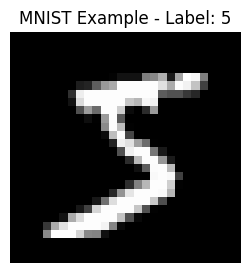

Image array shape: (28, 28)
Each image contains 28 x 28 grayscale pixel values.

SYSTEM LOG: Batch Size = 64
SYSTEM LOG: Learning Rate = 0.01
SYSTEM LOG: Maximum Images Used = 12288

SYSTEM LOG: Neural network created.

SYSTEM LOG: Starting training...

Update Step 0001 | Images Processed: 00064 | Current Loss: 2.9983
Update Step 0051 | Images Processed: 03264 | Current Loss: 0.7638
Update Step 0101 | Images Processed: 06464 | Current Loss: 0.6472
Update Step 0151 | Images Processed: 09664 | Current Loss: 0.6497

EXECUTION SUMMARY
Batch Size:               64
Total Images Processed:   12288
Total Update Steps:       192
Last Batch Loss:          0.3896
Total Hardware Time:      3.37 seconds

COPY THIS VERIFICATION KEY INTO CANVAS:
K-B64-L0.01-CPU


In [ ]:
# =====================================================================
# WEEK 1 LAB: DEEP LEARNING COMPONENTS - KERAS VERSION
# =====================================================================

"""
STUDENT EXPERIMENT GUIDE
----------------------------------------------------------------------
You are not expected to understand every line of code yet.

Your goals are to:
1. Run a complete deep learning system.
2. Identify its major components.
3. Change a few settings.
4. Observe how the system responds.
5. Compare this implementation with the PyTorch version.

We will go through the details together in class next week.

OBSERVATION: WHAT HARDWARE DID COLAB ASSIGN?
Run the cell and look for:

    SYSTEM LOG: Running on Hardware Accelerator: [CPU]

or:

    SYSTEM LOG: Running on Hardware Accelerator: [GPU]

For this lab, simply observe what Colab assigned.
You do not need to change the runtime hardware.

EXPERIMENT A: CHANGE THE LEARNING RATE
1. Find CONFIG_LEARNING_RATE below.
2. Change it from 0.01 to 10.0.
3. Run the entire cell again.
4. Watch "Current Loss."
5. Observe what happens when the learning rate is very large.

EXPERIMENT B: CHANGE THE BATCH SIZE
1. Change CONFIG_LEARNING_RATE back to 0.01.
2. Change CONFIG_BATCH_SIZE from 64 to 1.
3. Run the entire cell again.
4. Compare:
      - Total Update Steps
      - Total Images Processed
      - Total Hardware Time
5. Notice how many more update steps are required.

BEFORE USING THE DRAWING APP
1. Restore CONFIG_BATCH_SIZE to 64.
2. Restore CONFIG_LEARNING_RATE to 0.01.
3. Run this cell one final time.
4. Then run Cell 2 and test your own handwriting.
----------------------------------------------------------------------
"""

# =====================================================================
# IMPORTS
# =====================================================================

import time

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

from tensorflow import keras


# =====================================================================
# STUDENT CONFIGURATION
# =====================================================================

CONFIG_BATCH_SIZE = 64
CONFIG_LEARNING_RATE = 0.01

# Each experiment will process approximately the same number of images.
CONFIG_MAX_SAMPLES = 12288


# =====================================================================
# REPRODUCIBILITY
# Use a fixed random seed so runs begin from a similar model state.
# =====================================================================

keras.utils.set_random_seed(42)


# =====================================================================
# STEP 1: HARDWARE
# TensorFlow uses a compatible GPU when one is available.
# Otherwise, it uses the CPU.
# =====================================================================

gpu_devices = tf.config.list_physical_devices("GPU")
device_name = "GPU" if gpu_devices else "CPU"

print("\n" + "=" * 60)
print(f"SYSTEM LOG: Running on Hardware Accelerator: [{device_name}]")
print("=" * 60)


# =====================================================================
# STEP 2: DATA PIPELINE
#
# MNIST contains 28 x 28 grayscale images of handwritten digits.
#
# The Keras MNIST loader returns NumPy arrays.
#
# We then:
#   1. Convert pixels to floating-point values from 0 to 1
#   2. Apply the same normalization used in the PyTorch version
# =====================================================================

print("\nSYSTEM LOG: Loading the MNIST training dataset...")

(x_train, y_train), _ = keras.datasets.mnist.load_data()

x_train = x_train.astype("float32") / 255.0

x_train = (
    x_train - 0.1307
) / 0.3081


# =====================================================================
# INSPECT ONE TRAINING EXAMPLE
# The model receives an array representing a 28 x 28 grayscale image.
# =====================================================================

sample_image = x_train[0]
sample_label = y_train[0]

plt.figure(figsize=(3, 3))
plt.imshow(sample_image, cmap="gray")
plt.title(f"MNIST Example - Label: {sample_label}")
plt.axis("off")
plt.show()

print(f"Image array shape: {sample_image.shape}")
print("Each image contains 28 x 28 grayscale pixel values.\n")


# =====================================================================
# CREATE THE DATA PIPELINE
#
# tf.data groups examples into batches and shuffles the training data
# before it is passed to the model.
# =====================================================================

train_dataset = tf.data.Dataset.from_tensor_slices(
    (x_train, y_train)
)

train_dataset = train_dataset.shuffle(
    buffer_size=len(x_train),
    seed=42,
    reshuffle_each_iteration=False
)

train_dataset = train_dataset.batch(
    CONFIG_BATCH_SIZE
)

print(f"SYSTEM LOG: Batch Size = {CONFIG_BATCH_SIZE}")
print(f"SYSTEM LOG: Learning Rate = {CONFIG_LEARNING_RATE}")
print(f"SYSTEM LOG: Maximum Images Used = {CONFIG_MAX_SAMPLES}")


# =====================================================================
# STEP 3: MODEL ARCHITECTURE
#
# Input:
#   One 28 x 28 grayscale image
#
# Flatten:
#   Converts the image into 784 input values
#
# Hidden Layer:
#   128 learned units
#
# Output:
#   10 values representing classes 0 through 9
# =====================================================================

class Week1VanillaNet(keras.Model):

    def __init__(self):
        super().__init__()

        self.input_layer = keras.layers.Flatten()
        self.hidden_layer = keras.layers.Dense(128)
        self.output_layer = keras.layers.Dense(10)

    def call(self, x, training=False):

        # Convert each 28 x 28 image into 784 input values.
        x = self.input_layer(x)

        # Apply the hidden linear layer.
        x = self.hidden_layer(x)

        # Apply the ReLU activation function.
        x = tf.nn.relu(x)

        # Produce 10 output scores, one for each digit class.
        x = self.output_layer(x)

        return x


model_e = Week1VanillaNet()

# Keras creates layer weights when the model first sees an input.
# Run one dummy input now so model initialization is complete
# before the training timer starts.
_ = model_e(
    tf.zeros((1, 28, 28), dtype=tf.float32),
    training=False
)

print("\nSYSTEM LOG: Neural network created.")


# =====================================================================
# STEP 4: LOSS FUNCTION AND OPTIMIZER
#
# Loss function:
#   Measures the difference between the model's output and the correct
#   class labels.
#
# GradientTape:
#   Records operations so TensorFlow can compute gradients.
#
# Optimizer:
#   Uses those gradients to update the model parameters.
# =====================================================================

criterion = keras.losses.SparseCategoricalCrossentropy(
    from_logits=True
)

optimizer = keras.optimizers.SGD(
    learning_rate=CONFIG_LEARNING_RATE
)


# =====================================================================
# STEP 5: TRAINING LOOP
#
# For each batch:
#
#   1. Read the current batch
#   2. Run the model
#   3. Compute the loss
#   4. Compute gradients
#   5. Update the model parameters
# =====================================================================

print("\nSYSTEM LOG: Starting training...\n")

start_time = time.time()

step_count = 0
samples_processed = 0

if CONFIG_BATCH_SIZE == 1:
    PRINT_EVERY = 1000
else:
    PRINT_EVERY = 50

for batch_idx, (data, target) in enumerate(train_dataset):

    # Record the forward pass so TensorFlow can compute gradients.
    with tf.GradientTape() as tape:

        # Forward pass.
        output = model_e(data, training=True)

        # Compute loss.
        loss = criterion(target, output)

    # Compute gradients for all trainable model parameters.
    gradients = tape.gradient(
        loss,
        model_e.trainable_variables
    )

    # Update model parameters.
    optimizer.apply_gradients(
        zip(gradients, model_e.trainable_variables)
    )

    step_count += 1
    samples_processed += int(data.shape[0])

    # Print a progress update at regular intervals.
    if batch_idx % PRINT_EVERY == 0:
        print(
            f"Update Step {step_count:04d} | "
            f"Images Processed: {samples_processed:05d} | "
            f"Current Loss: {loss.numpy():.4f}"
        )

    # Stop after approximately the same number of images in each run.
    if samples_processed >= CONFIG_MAX_SAMPLES:
        break


# =====================================================================
# TRAINING SUMMARY
# =====================================================================

# Reading the final loss value ensures pending TensorFlow work is complete
# before the elapsed time is reported.
last_loss = float(loss.numpy())

end_time = time.time()
elapsed = end_time - start_time

print("\n" + "=" * 60)
print("EXECUTION SUMMARY")
print(f"Batch Size:               {CONFIG_BATCH_SIZE}")
print(f"Total Images Processed:   {samples_processed}")
print(f"Total Update Steps:       {step_count}")
print(f"Last Batch Loss:          {last_loss:.4f}")
print(f"Total Hardware Time:      {elapsed:.2f} seconds")
print("=" * 60)


# =====================================================================
# VERIFICATION KEY
# =====================================================================

verification_key = (
    f"K-B{CONFIG_BATCH_SIZE}-"
    f"L{CONFIG_LEARNING_RATE}-"
    f"{device_name}"
)

print(
    "\nCOPY THIS VERIFICATION KEY INTO CANVAS:"
    f"\n{verification_key}"
)


In [ ]:
# =====================================================================
# STEP 6: INTERACTIVE INFERENCE
#
# This cell creates a drawing canvas in Colab.
#
# Draw a digit from 0 through 9 and click "Recognize."
# The drawing will be converted into the same 28 x 28 input format
# used by the model during training.
# =====================================================================

import base64

import cv2
import IPython
import numpy as np

from google.colab import output


# =====================================================================
# DRAWING INTERFACE
#
# This HTML and JavaScript creates a 280 x 280 drawing canvas.
# The larger canvas makes it easier to draw with a mouse or touchscreen.
#
# When "Recognize" is clicked, the canvas image is sent to Python.
# =====================================================================

canvas_html = """
<div style="
    border: 2px solid #5f6368;
    border-radius: 8px;
    padding: 15px;
    width: 320px;
    background-color: #202124;
    text-align: center;
    font-family: sans-serif;
    color: white;
">
    <h3 style="margin-top: 0; color: #aecbfa;">
        Draw a Digit (0-9)
    </h3>

    <canvas
        id="canvas"
        width="280"
        height="280"
        style="
            border: 1px dashed #5f6368;
            background: black;
            cursor: crosshair;
            border-radius: 4px;
            touch-action: none;
        ">
    </canvas>

    <div style="margin-top: 15px;">
        <button
            id="clearBtn"
            style="
                background: #3c4043;
                color: white;
                border: none;
                padding: 8px 16px;
                border-radius: 4px;
                cursor: pointer;
                margin-right: 10px;
            ">
            Clear
        </button>

        <button
            id="predictBtn"
            style="
                background: #8ab4f8;
                color: #202124;
                border: none;
                padding: 8px 16px;
                border-radius: 4px;
                font-weight: bold;
                cursor: pointer;
            ">
            Recognize
        </button>
    </div>
</div>

<script>
    var canvas = document.getElementById('canvas');
    var ctx = canvas.getContext('2d');

    // Configure the drawing stroke.
    ctx.lineWidth = 20;
    ctx.lineCap = 'round';
    ctx.strokeStyle = 'white';

    var drawing = false;


    // ---------------------------------------------------------------
    // Mouse input
    // ---------------------------------------------------------------

    canvas.addEventListener('mousedown', function(e) {
        drawing = true;

        var rect = canvas.getBoundingClientRect();

        ctx.beginPath();
        ctx.moveTo(
            e.clientX - rect.left,
            e.clientY - rect.top
        );
    });

    canvas.addEventListener('mousemove', function(e) {
        if (!drawing) return;

        var rect = canvas.getBoundingClientRect();

        ctx.lineTo(
            e.clientX - rect.left,
            e.clientY - rect.top
        );

        ctx.stroke();
    });

    canvas.addEventListener('mouseup', function() {
        drawing = false;
    });

    canvas.addEventListener('mouseleave', function() {
        drawing = false;
    });


    // ---------------------------------------------------------------
    // Touch input
    // ---------------------------------------------------------------

    canvas.addEventListener('touchstart', function(e) {
        e.preventDefault();
        drawing = true;

        var touch = e.touches[0];
        var rect = canvas.getBoundingClientRect();

        ctx.beginPath();
        ctx.moveTo(
            touch.clientX - rect.left,
            touch.clientY - rect.top
        );
    });

    canvas.addEventListener('touchmove', function(e) {
        e.preventDefault();

        if (!drawing) return;

        var touch = e.touches[0];
        var rect = canvas.getBoundingClientRect();

        ctx.lineTo(
            touch.clientX - rect.left,
            touch.clientY - rect.top
        );

        ctx.stroke();
    });

    canvas.addEventListener('touchend', function() {
        drawing = false;
    });


    // ---------------------------------------------------------------
    // Clear the canvas
    // ---------------------------------------------------------------

    document.getElementById('clearBtn').addEventListener('click', function() {
        ctx.clearRect(0, 0, canvas.width, canvas.height);
    });


    // ---------------------------------------------------------------
    // Send the drawing to Python for inference
    // ---------------------------------------------------------------

    document.getElementById('predictBtn').addEventListener('click', function() {

        // Convert the canvas into a PNG image.
        var dataUrl = canvas.toDataURL('image/png');

        // Send the image to the registered Python callback.
        google.colab.kernel.invokeFunction(
            'notebook.PredictDigitKeras',
            [dataUrl],
            {}
        );
    });

</script>
"""


# =====================================================================
# PROCESS THE DRAWING AND RUN INFERENCE
# =====================================================================

def process_and_predict(data_url):
    """
    Receive the drawing from the browser, convert it into the same
    general input format used during training, and run the trained model.
    """

    # -----------------------------------------------------------------
    # 1. Decode the PNG image sent from JavaScript.
    # -----------------------------------------------------------------

    header, encoded = data_url.split(",", 1)
    image_bytes = base64.b64decode(encoded)

    image_array = np.frombuffer(
        image_bytes,
        np.uint8
    )

    img = cv2.imdecode(
        image_array,
        cv2.IMREAD_UNCHANGED
    )


    # -----------------------------------------------------------------
    # 2. Extract the drawing.
    #
    # The canvas PNG includes an alpha channel.
    # The drawn strokes are opaque and the untouched background is
    # transparent, so the alpha channel gives us the digit image.
    # -----------------------------------------------------------------

    if img.ndim == 3 and img.shape[2] == 4:
        img = img[:, :, 3]


    # -----------------------------------------------------------------
    # 3. Resize from 280 x 280 to 28 x 28.
    #
    # MNIST images are 28 x 28 pixels, so the model expects that size.
    # -----------------------------------------------------------------

    img_resized = cv2.resize(
        img,
        (28, 28),
        interpolation=cv2.INTER_AREA
    )


    # -----------------------------------------------------------------
    # 4. Normalize the pixels.
    #
    # These are the same normalization values used in the training
    # pipeline in Cell 1.
    # -----------------------------------------------------------------

    img_normalized = (
        (img_resized / 255.0) - 0.1307
    ) / 0.3081


    # -----------------------------------------------------------------
    # 5. Convert the image into a TensorFlow tensor.
    #
    # The model expects a batch of images:
    #
    #   [batch, height, width]
    #
    # so one image becomes:
    #
    #   [1, 28, 28]
    # -----------------------------------------------------------------

    input_tensor = tf.convert_to_tensor(
        img_normalized,
        dtype=tf.float32
    )

    input_tensor = tf.expand_dims(
        input_tensor,
        axis=0
    )


    # -----------------------------------------------------------------
    # 6. Run inference.
    #
    # training=False tells Keras that we are making a prediction,
    # not training the model.
    # -----------------------------------------------------------------

    output = model_e(
        input_tensor,
        training=False
    )

    # Select the class with the largest output value.
    prediction = int(
        tf.argmax(
            output,
            axis=1
        ).numpy()[0]
    )

    # Convert the 10 output values into relative scores.
    scores = tf.nn.softmax(
        output,
        axis=1
    )[0]

    model_score = float(
        scores[prediction].numpy()
    ) * 100


    # -----------------------------------------------------------------
    # 7. Display the result.
    # -----------------------------------------------------------------

    IPython.display.clear_output(
        wait=True
    )

    display(
        IPython.display.HTML(canvas_html)
    )

    print("\nMODEL PREDICTION")
    print(f"Predicted Digit: {prediction}")
    print(f"Model Score:     {model_score:.2f}%")


# =====================================================================
# CONNECT JAVASCRIPT TO PYTHON
#
# The JavaScript "Recognize" button calls this registered function.
# =====================================================================

output.register_callback(
    'notebook.PredictDigitKeras',
    process_and_predict
)


# =====================================================================
# DISPLAY THE DRAWING INTERFACE
# =====================================================================

IPython.display.clear_output()

display(
    IPython.display.HTML(canvas_html)
)



MODEL PREDICTION
Predicted Digit: 2
Model Score:     55.36%
